# Experiments
See tex/final/tesi.pdf, Sections 2 to 4.

The union bound and Rademacher experiments use Gaussian noise with $\sigma = 3.5$, which flips 20% of the labels like Bernoulli noise with $p = 0.8$. The best risk experiments use Bernoulli noise with $p = 0.8$. When the noise level varies, we use $p \in \{0.6, 0.8, 0.95\}$, i.e. 40%, 20%, 5% noise, and for the Gaussian noise the values of $\sigma$ that flip the same fraction of labels.

In [28]:
%run base.ipynb

mare


In [29]:
# MODEL
mymodel = DecisionTreeClassifier

# PARAMETERS
supp_size = 10_000
data_size_test = 200_000
data_size_tr = 50
num_iter = 100
num_crossings = 10
my_nums_crossings = [5, 10, 50]
# bernoulli noise (best risk)
noise_p = 0.8
my_noise_ps = [0.6, 0.8, 0.95]

from functools import partial
from scipy.stats import norm
sine_f = partial(sine, m = num_crossings)

def noise_label(p):
    # noise level as percentage of flipped labels
    return f'{(1 - p) * 100:.0f}% noise'

def sigma_for_p(f, p, N = supp_size, l = 0.0, u = 10.0):
    # sigma such that gaussian noise flips on average the same fraction 1 - p of labels
    # as bernoulli noise: P(flip | x) = Phi(-|f(x)|/sigma), averaged over the uniform support.
    # rounded to 0.5
    x = np.linspace(l, u, N)
    sigma = brentq(lambda s: norm.cdf(-np.abs(f(x)) / s).mean() - (1 - p), 1e-3, 1e3)
    return np.round(2 * sigma) / 2

# gaussian noise (union bound and rademacher), same noise levels as the bernoulli one
noise_sigma = sigma_for_p(sine_f, noise_p)
my_noise_sigmas = [sigma_for_p(sine_f, p) for p in my_noise_ps]
print('sigma:', noise_sigma, ' sigmas:', my_noise_sigmas)

# same depths that main_loop and plots use
depths, _ = get_depths_list(np.log2(data_size_tr), mymodel)

# figures used in the thesis
out_dir = '../tex/final/outputs/'

sigma: 3.5  sigmas: [np.float64(12.5), np.float64(3.5), np.float64(1.0)]


## Union bound

We plot
\begin{equation}
\mathbb E_D[R(\hat h_D) - \hat R_D(\hat h_D)] \le \sqrt{\frac{d}{n}}
\end{equation}
obtained by Theorem 2.5 in Section 2 and $\log \vert\mathcal H_d\vert \le d$.

[checkpoint] bound: "unionbound" -> union_bound, params: []


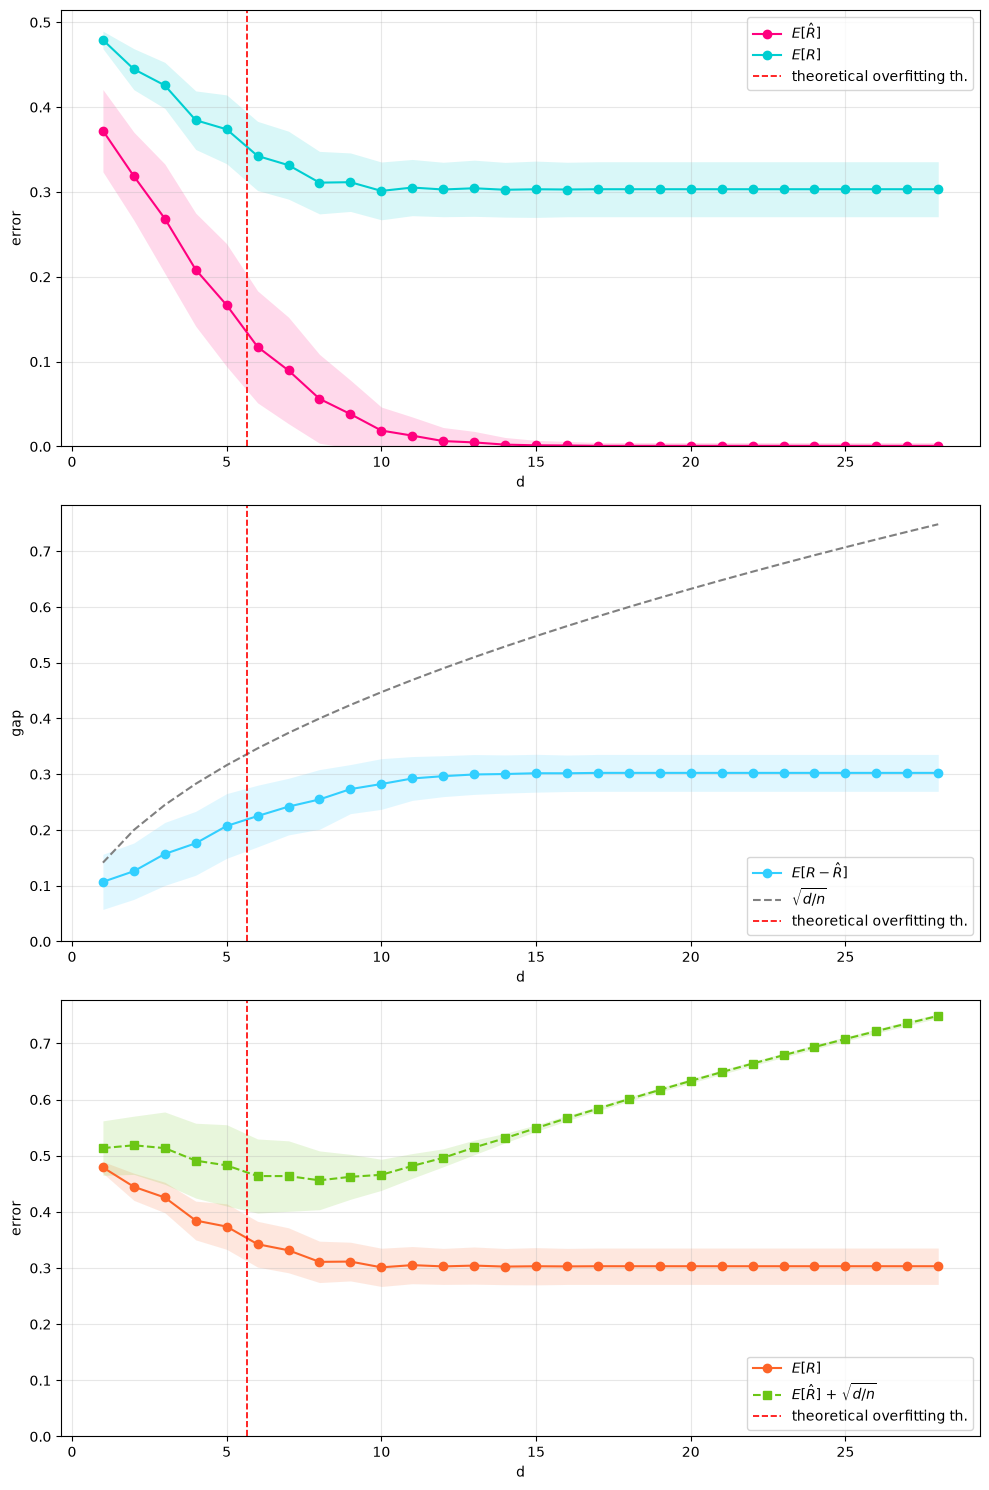

In [30]:
# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y(x = x_test, f = sine_f, sigma = noise_sigma)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, sigma = noise_sigma, T = num_iter, model = mymodel,
    f = sine_f, noise_type = "gaussian",
    N = supp_size)

fig, axs = plt.subplots(3, 1, figsize=(10, 15))
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, noise_type = "gaussian", sigma = noise_sigma, T = num_iter, model = mymodel, 
      axes = axs, bound_name = "unionbound", bound_params = {}
      )
plt.tight_layout()
fig.savefig(out_dir + 'pic1.png', bbox_inches='tight')
plt.show()

## Rademacher + Massart

We plot

\begin{equation}
\mathbb E_D[R(\hat h_D) - \hat R_D(\hat h_D)] \le \min\left\{\sqrt{\frac{d}{n}}, 1\right\}
\end{equation}

obtained from $N(D) \le \min\{\vert \mathcal H\vert, 2^n\}$, equation (58). Same models as above, only the bound changes.

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


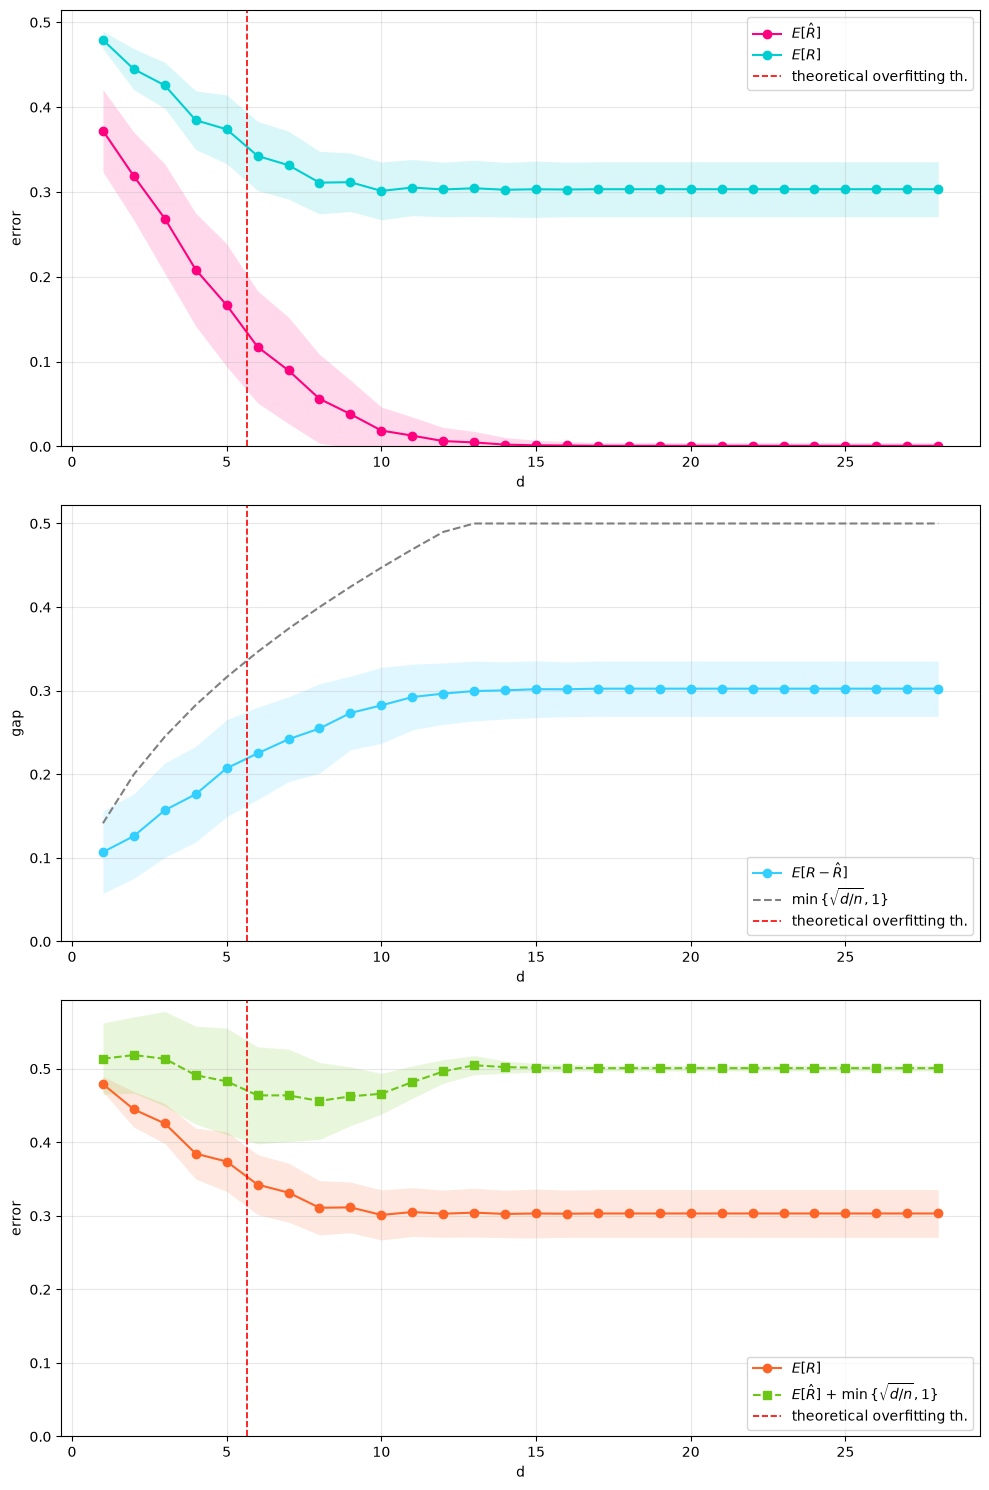

In [31]:
fig, axs = plt.subplots(3, 1, figsize=(10, 15))
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, noise_type = "gaussian", sigma = noise_sigma, T = num_iter, model = mymodel, 
      axes = axs, bound_name = "rademmassart", bound_params = {}
      )
plt.tight_layout()
fig.savefig(out_dir + 'pic2.png', bbox_inches='tight')
plt.show()

### vedi che non si sposta con il rumore!

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


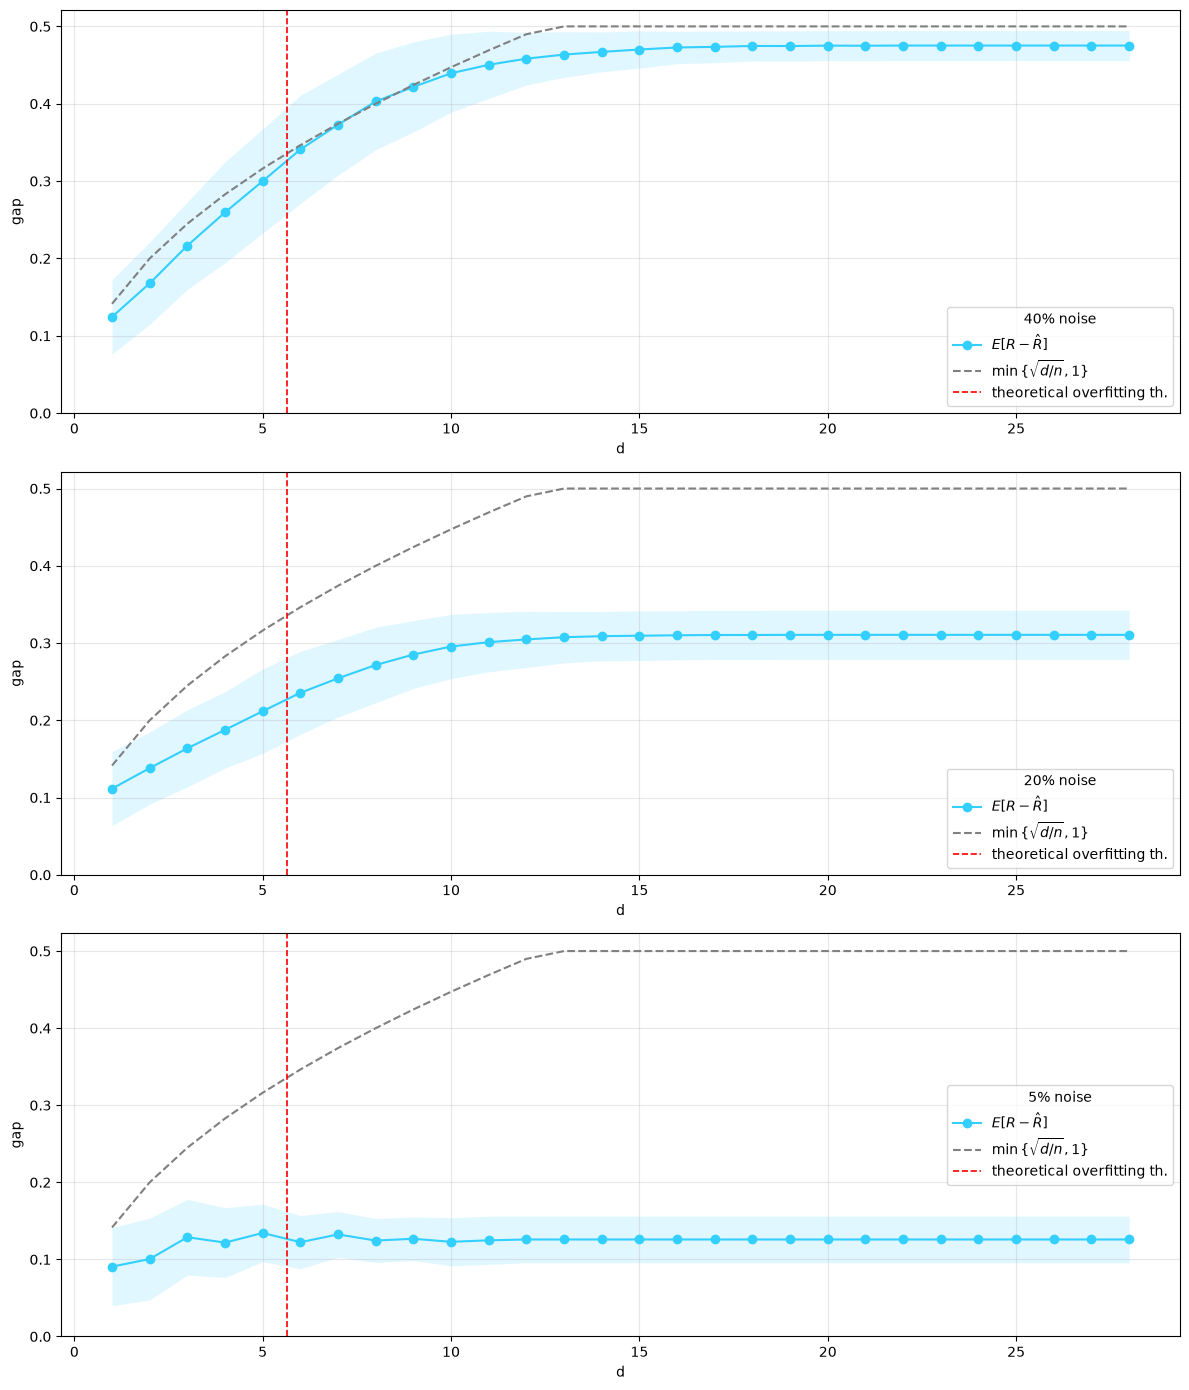

In [32]:
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

for ax, my_noise_p, my_noise_sigma in zip(axs.flat, my_noise_ps, my_noise_sigmas):
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=sine_f, sigma=my_noise_sigma)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, noise_type = "gaussian",
        sigma=my_noise_sigma, T=num_iter, model=mymodel, f=sine_f, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, noise_type = "gaussian", sigma=my_noise_sigma, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "rademmassart", bound_params = {})
    ax.legend(title=noise_label(my_noise_p))

plt.tight_layout()
fig.savefig(out_dir + 'pic3.png', bbox_inches='tight')
plt.show()

### e con la complessità della funzione?

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


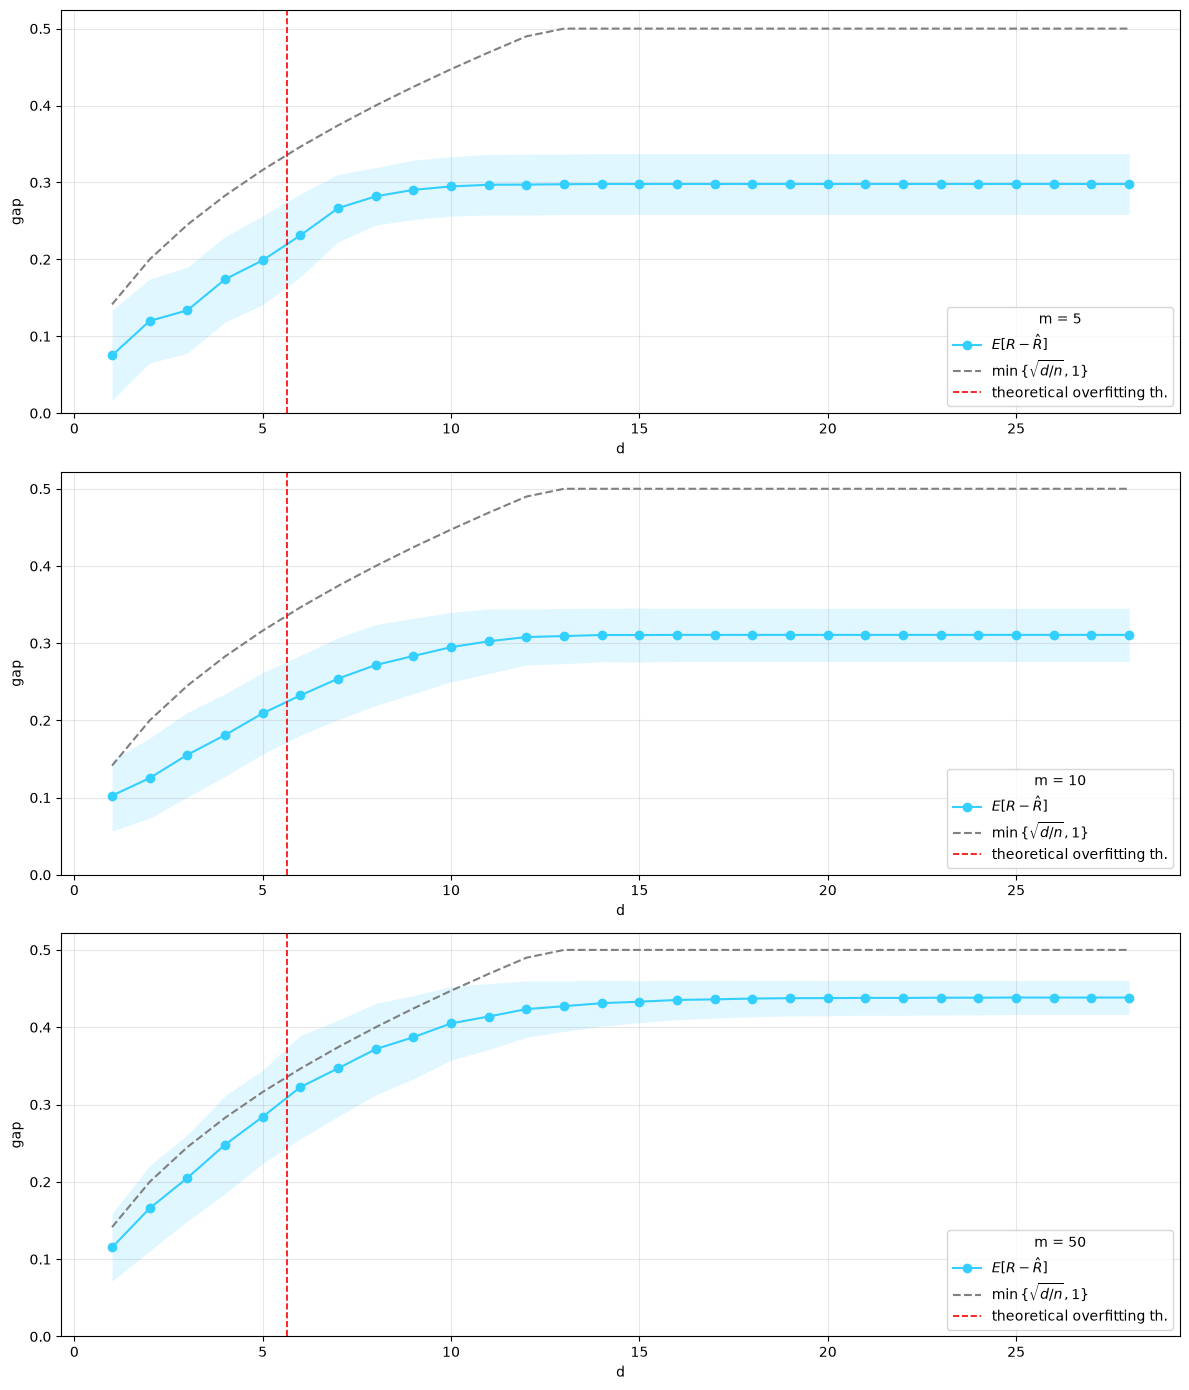

In [33]:
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

for ax, my_num_crossings in zip(axs.flat, my_nums_crossings):
    my_sine_f = partial(sine, m = my_num_crossings)
    # same noise level for every m
    my_noise_sigma = sigma_for_p(my_sine_f, noise_p)
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y(x=x_test, f=my_sine_f, sigma=my_noise_sigma)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, noise_type = "gaussian",
        sigma=my_noise_sigma, T=num_iter, model=mymodel, f=my_sine_f, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, noise_type = "gaussian", sigma=my_noise_sigma, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "rademmassart", bound_params = {})
    ax.legend(title=f'm = {my_num_crossings}')

plt.tight_layout()
plt.show()

## Bounds with the best risk

The bound is 

\begin{equation}
 \min\left\{ 
\sqrt{\frac{(A_{\mathcal H}+\sigma^2)\log \vert\mathcal H \vert}{n}} + \frac{\log\vert\mathcal H \vert}{n} ,
\sqrt{A_{\mathcal H}+\sigma^2} \right\}
\end{equation}

Let's first see the Bayes risk (irreducible noise), the minimum risk achievable by our hypotheses, and their difference (approximation error).

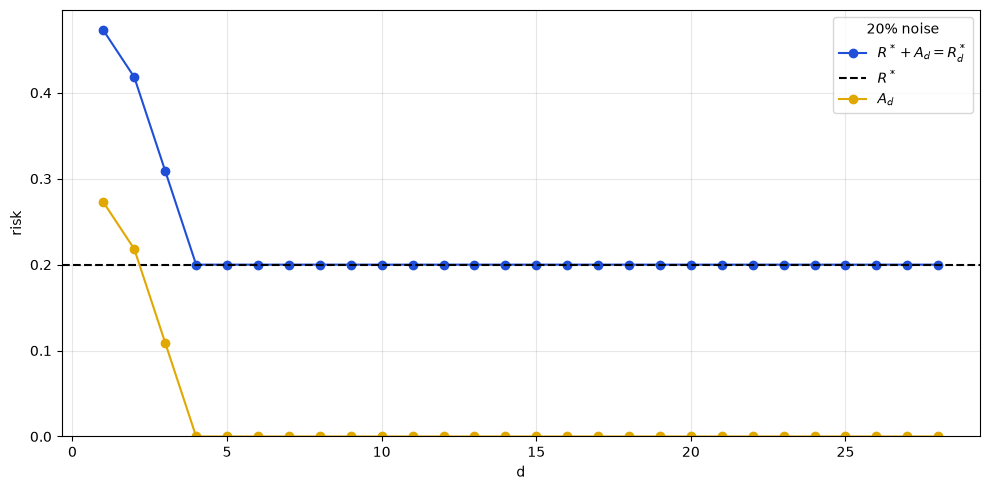

In [34]:
R_star_d = dp_R_star_d(sine_f, depths, N = supp_size, p = noise_p)

R_star = 1-noise_p

A_d = R_star_d - R_star

def plot_noise_approxerr(ax, depths, R_star_d, R_star, legend_title=None):
    # colors on purpose different from the ones used in plots() for the errors
    ax.plot(depths, R_star_d, color='#1F4FD8', marker='o', label=r'$R^* + A_d = R^*_d$')
    ax.axhline(R_star, color='k', linestyle='--', label=r'$R^*$')
    ax.plot(depths, R_star_d - R_star, color='#E0A800', marker='o', label=r'$A_d$')
    ax.set_ylim(bottom=0)
    ax.set_xlabel('d'); ax.set_ylabel('risk')
    ax.legend(title=legend_title); ax.grid(True, alpha=0.3)

fig, ax = plt.subplots(figsize=(10, 5))
plot_noise_approxerr(ax, depths, R_star_d, R_star, legend_title=noise_label(noise_p))
plt.tight_layout()
plt.show()

[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


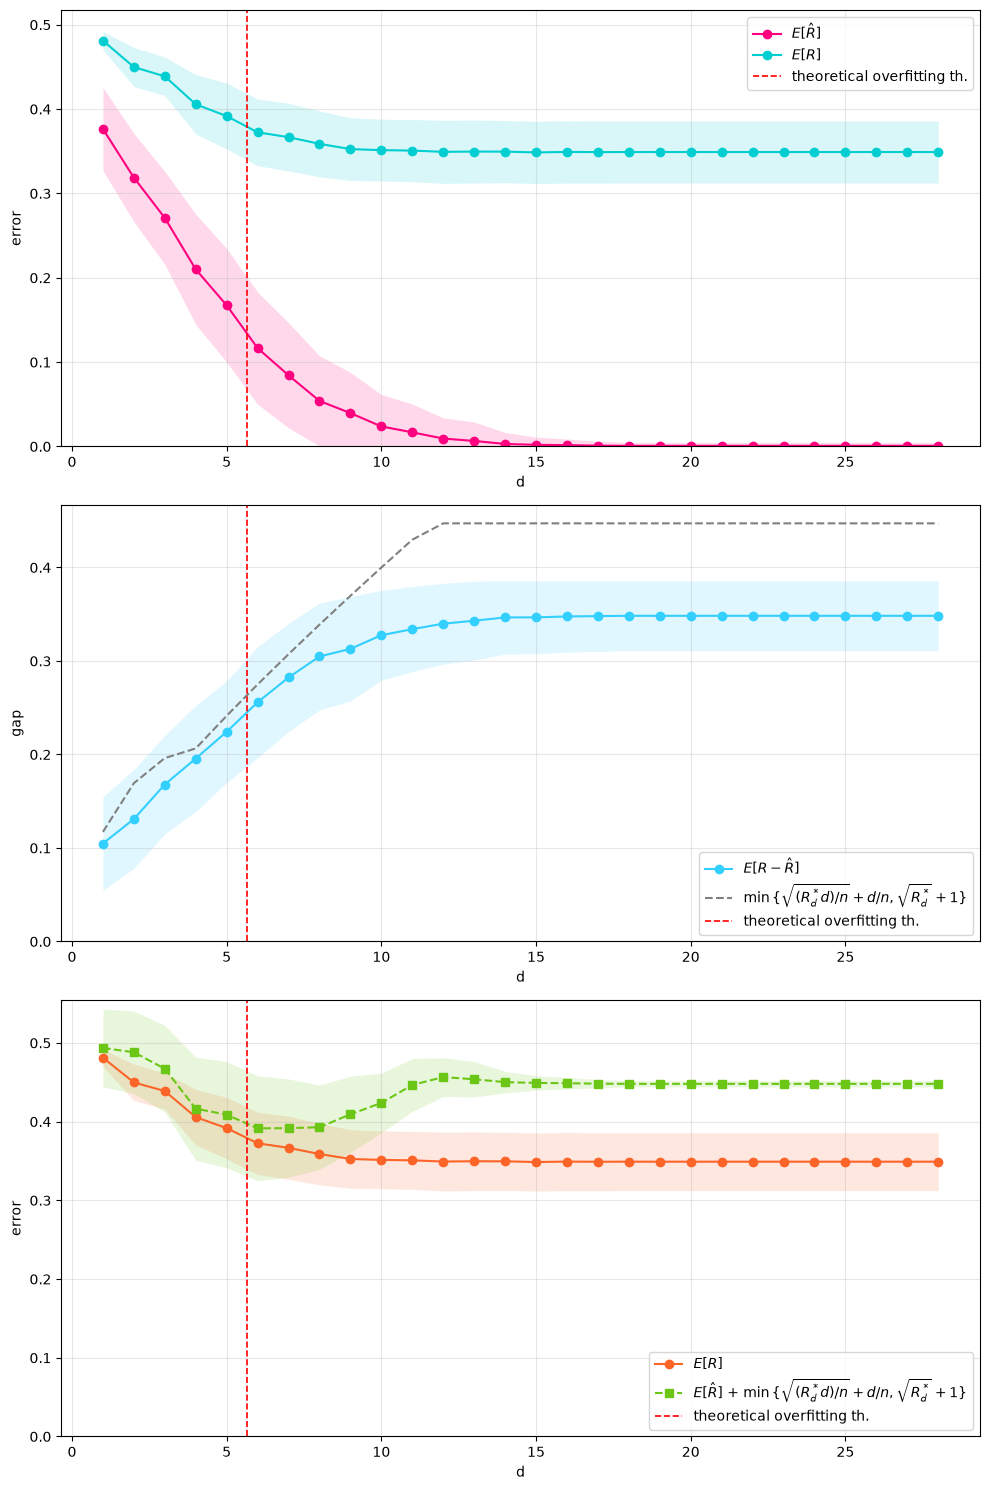

In [35]:
# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y_bernoulli(x = x_test, f = sine_f, p = noise_p)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, p = noise_p, T = num_iter, model = mymodel,
    f = sine_f, noise_type = "bernoulli",
    N = supp_size)

fig, axs = plt.subplots(3, 1, figsize=(10, 15))
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, noise_type = "bernoulli", p = noise_p, T = num_iter, model = mymodel, 
      axes = axs, bound_name = "noiseapproxerr", bound_params = {"R_star_d": R_star_d}
      )
plt.tight_layout()
fig.savefig(out_dir + 'pic4.png', bbox_inches='tight')
plt.show()

Let's see it changing!

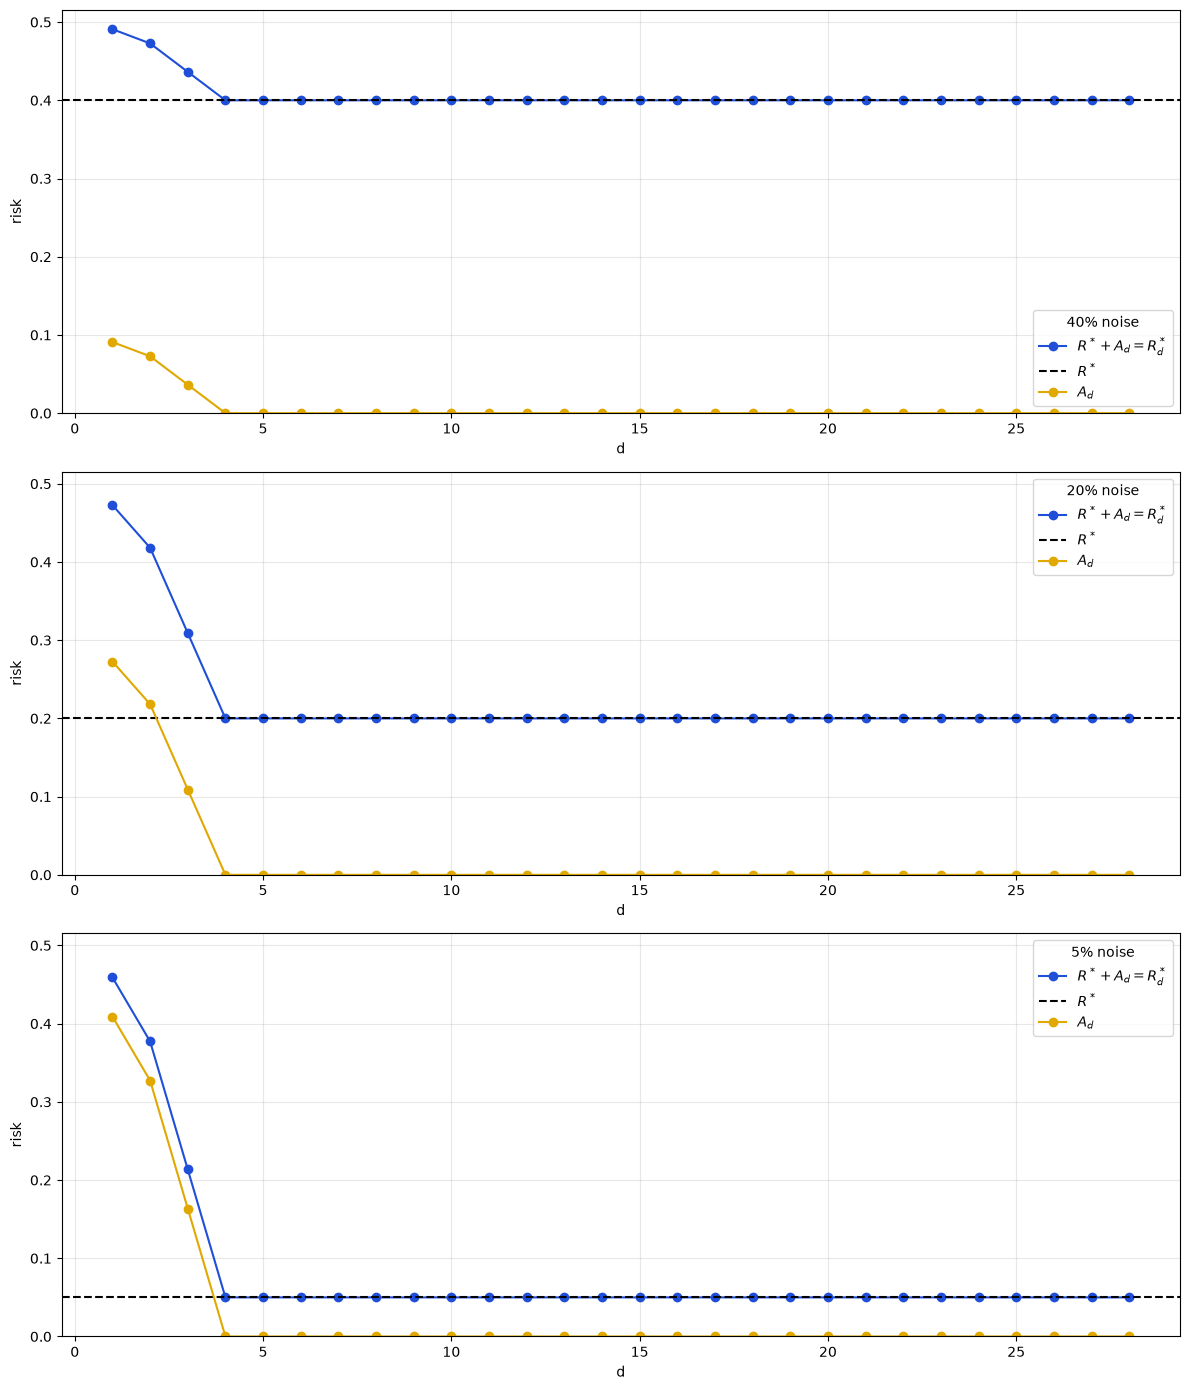

In [36]:
# R^*_d for each noise level, to reuse in the bounds below
R_star_d_by_p = {}

fig, axs = plt.subplots(3, 1, figsize=(12, 14), sharey=True)

for ax, my_noise_p in zip(axs, my_noise_ps):
    my_R_star_d = dp_R_star_d(sine_f, depths, N = supp_size, p = my_noise_p)
    my_R_star = 1-my_noise_p
    R_star_d_by_p[my_noise_p] = my_R_star_d

    plot_noise_approxerr(ax, depths, my_R_star_d, my_R_star, legend_title=noise_label(my_noise_p))

# shared y axis: fix the top by hand, set_ylim(bottom=0) freezes it on the first panel
axs[0].set_ylim(0, 1.05 * max(r.max() for r in R_star_d_by_p.values()))

plt.tight_layout()
fig.savefig(out_dir + 'pic5.png', bbox_inches='tight')
plt.show()

[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']
[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']
[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


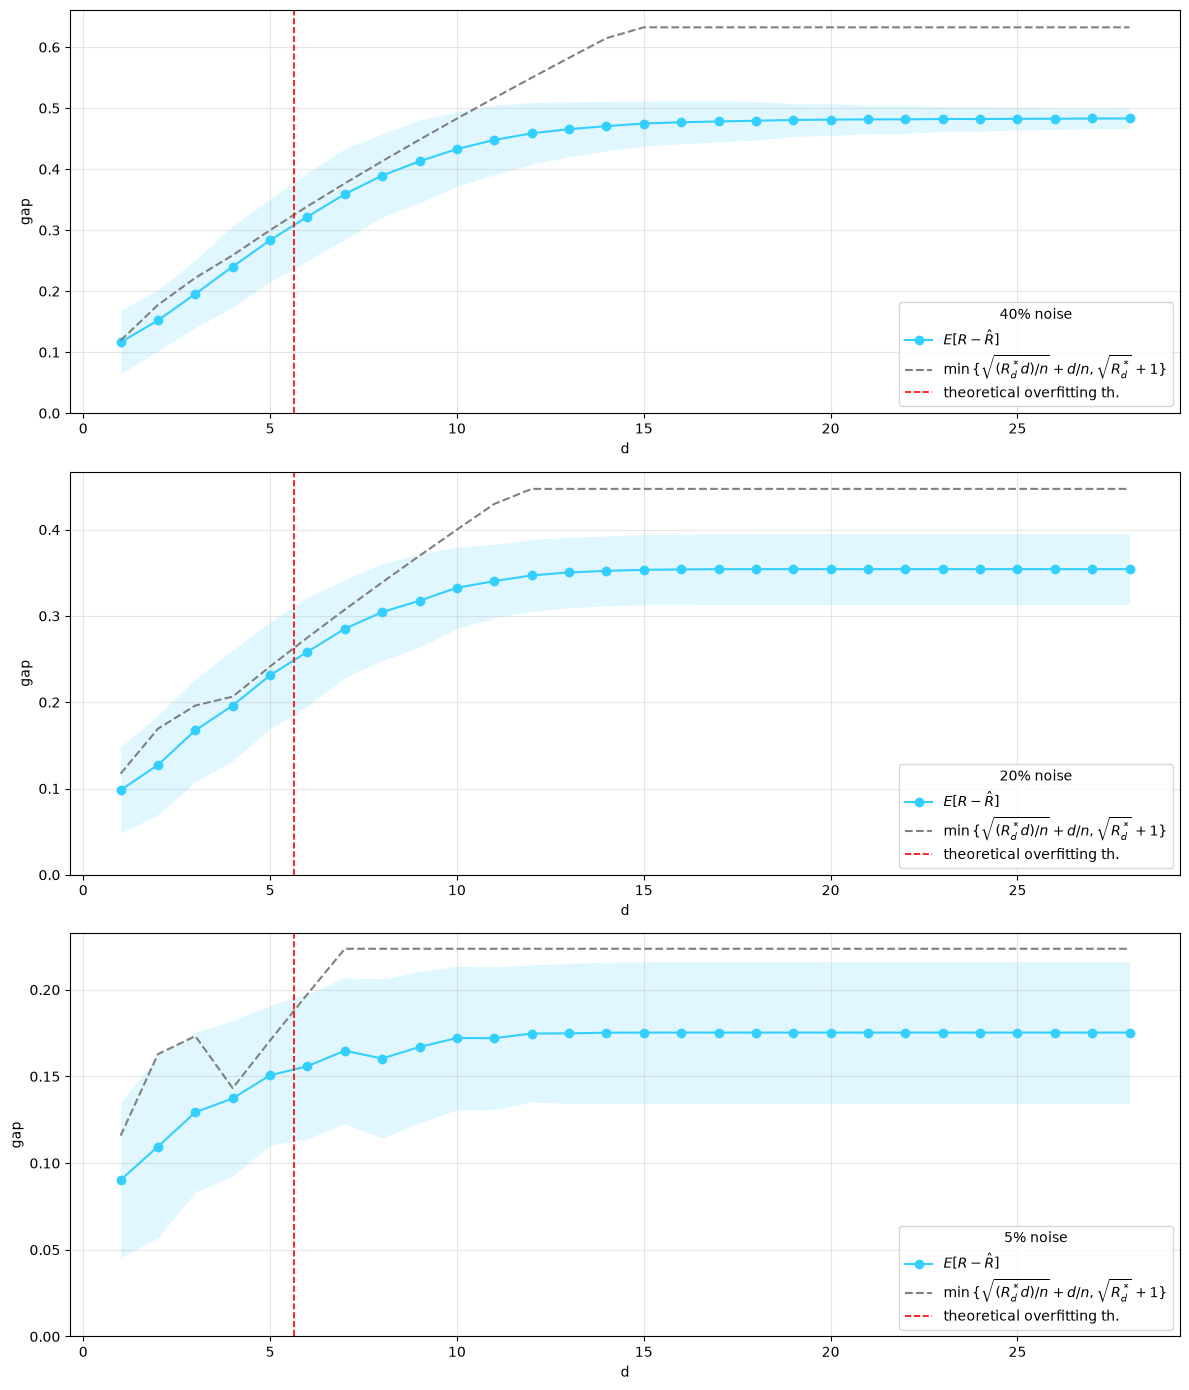

In [37]:
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

for ax, my_noise_p in zip(axs.flat, my_noise_ps):
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y_bernoulli(x=x_test, f=sine_f, p=my_noise_p)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, noise_type = "bernoulli",
        p=my_noise_p, T=num_iter, model=mymodel, f=sine_f, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, noise_type = "bernoulli", p=my_noise_p, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "noiseapproxerr", bound_params = {"R_star_d": R_star_d_by_p[my_noise_p]})
    ax.legend(title=noise_label(my_noise_p))

plt.tight_layout()
fig.savefig(out_dir + 'pic6.png', bbox_inches='tight')
plt.show()

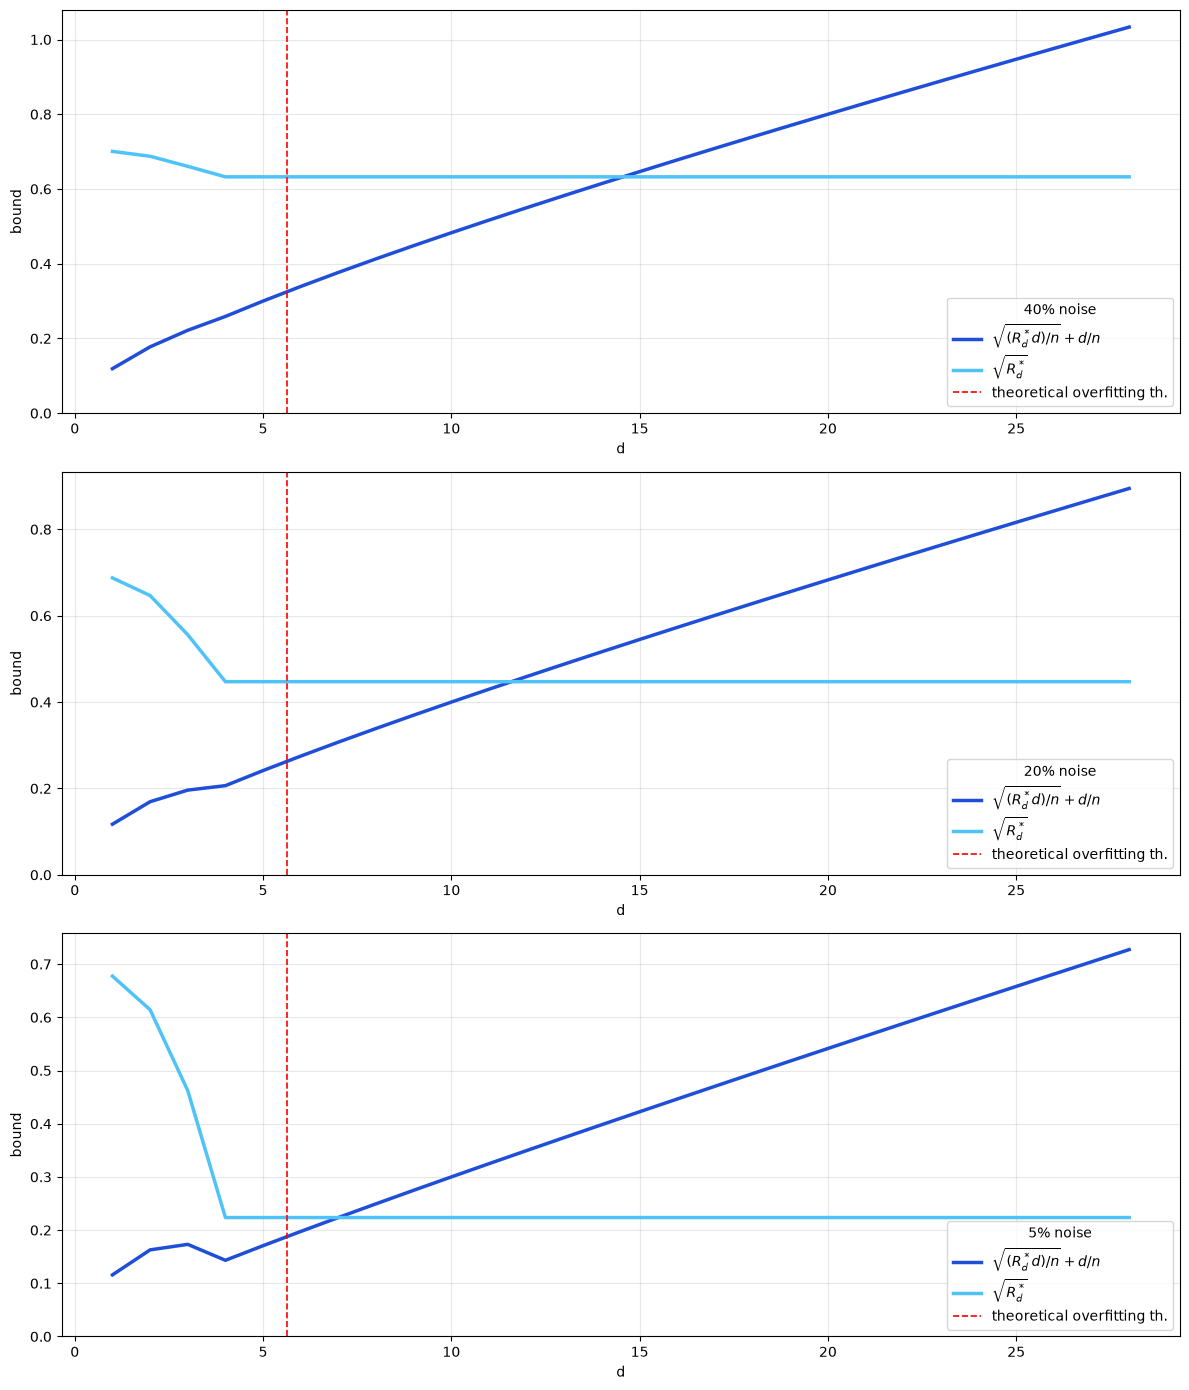

In [38]:
# plot the two terms of the bound 
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

for ax, my_noise_p in zip(axs.flat, my_noise_ps):
    my_R_star_d = R_star_d_by_p[my_noise_p]
    log_H = log_card_H(depths)

    # same two terms as in noise_approxerr_bound
    term_one = np.sqrt((my_R_star_d * log_H) / data_size_tr) + log_H / data_size_tr
    term_two = np.sqrt(my_R_star_d)

    ax.plot(depths, term_one, color='#1F4FD8', linewidth=2.5, label=r'$\sqrt{(R^*_d d)/n} + d/n$')
    ax.plot(depths, term_two, color='#4FC3F7', linewidth=2.5, label=r'$\sqrt{R^*_d}$')
    ax.axvline(np.log2(data_size_tr), color='red', linestyle='--', linewidth=1.2, label='theoretical overfitting th.')
    ax.set_ylim(bottom=0)
    ax.set_xlabel('d'); ax.set_ylabel('bound')
    ax.legend(loc='lower right', title=noise_label(my_noise_p)); ax.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(out_dir + 'pic7.png', bbox_inches='tight')
plt.show()


Same gap and bound as above, at fixed noise, for target functions with different number of crossings $m$.

In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

for ax, my_num_crossings in zip(axs.flat, my_nums_crossings):
    my_sine_f = partial(sine, m = my_num_crossings)
    my_R_star_d = dp_R_star_d(my_sine_f, depths, N = supp_size, p = noise_p)

    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y_bernoulli(x=x_test, f=my_sine_f, p=noise_p)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, noise_type = "bernoulli",
        p=noise_p, T=num_iter, model=mymodel, f=my_sine_f, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, noise_type = "bernoulli", p=noise_p, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "noiseapproxerr", bound_params = {"R_star_d": my_R_star_d})
    ax.legend(title=f'm = {my_num_crossings}')

plt.tight_layout()
plt.show()